# 03. Models: benchmarks and random forest

This notebook builds the first forecasting model and compares it with the two forecasts a client could already use today.

| | File | Content |
|---|---|---|
| Input | `features_table.parquet` | From `02_features.ipynb`: target, model inputs, Elia benchmark, daylight and split flags, for the working area |
| Input | `features.json` | The list of model inputs |
| Output | `model_settings.json` | The settings chosen for the random forest and its validation scores |
| Output | `cv_predictions.parquet` | The validation forecasts of every model, hour by hour, for charts in the report |

**What happens here**

1. The two benchmarks are scored: the naive rule (persistence) and Elia's own day-ahead forecast.
2. A random forest (Session 4 of the course) is tuned and scored.
3. The three are compared, and the forest is opened up to see which inputs it relies on.

**The test period is not opened in this notebook.** Every number below comes from the training period only, using validation folds ordered in time (section 3). The test period is scored once, at the end, in the evaluation notebook.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

TABLE_FILE = Path("features_table.parquet")
FEATURES_FILE = Path("features.json")
SETTINGS_FILE = Path("model_settings.json")
PRED_FILE = Path("cv_predictions.parquet")

N_FOLDS = 4          # number of validation blocks
FOLD_MONTHS = 3      # length of each validation block, in months
N_TREES = 300        # trees in the forest ("a few hundred": more trees never overfit, Session 4)
SEED = 0             # fixes the random draws so that results can be reproduced

# chart style (same as the other notebooks)
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
BLUE_LIGHT = "#b7d3f6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:,.2f}".format)

# one name and one colour per forecast, used in every table and chart
NAMES = {"persistence": "Persistence (naive rule)", "elia": "Elia day-ahead forecast", "rf": "Random forest"}
COLORS = {"persistence": MUTED, "elia": ORANGE, "rf": BLUE}

## 1. Load the training period

The test rows are dropped in the first lines, so nothing below can read them by accident.

In [2]:
info = json.loads(FEATURES_FILE.read_text())
PROVINCE, FEATURES = info["province"], info["features"]

full = pd.read_parquet(TABLE_FILE).sort_values("datetime").reset_index(drop=True)
TEST_START = full.loc[full["split"] == "test", "datetime"].min()
df = full[full["split"] == "train"].reset_index(drop=True)
print(f"Test period set aside without being read: {len(full) - len(df):,} rows from {TEST_START:%d %B %Y}")
del full

day = df[df["is_daylight"]].copy()        # the rows the models are trained and scored on
print(f"{PROVINCE}, training period: {df['datetime'].min():%d %B %Y} to {df['datetime'].max():%d %B %Y}")
print(f"{len(df):,} hourly rows, of which {len(day):,} in daylight")
print(f"{len(FEATURES)} model inputs")

Test period set aside without being read: 8,760 rows from 26 October 2025
Antwerp, training period: 15 March 2024 to 25 October 2025
14,159 hourly rows, of which 7,986 in daylight
28 model inputs


## 2. How a forecast is scored

Every forecast is expressed as a **load factor**: output divided by installed capacity, between 0 and 1. The error is shown in **percentage points of capacity**. An error of 5 points on a 100 MW portfolio is 5 MW sold wrongly in that hour.

| Measure | What it is | How to read it |
|---|---|---|
| **MAE** | The average size of the error, ignoring its sign | The main score. A trader pays for every MW of error, so the average size is what matters |
| **RMSE** | Like MAE, but large errors count more | Shows whether a forecast makes rare, very large errors |
| **Bias** | The average error, keeping its sign | Above zero: the forecast is too high on average. Below zero: too low |

Lower MAE and RMSE are better. Bias should be close to zero.

Only **daylight hours** are scored. At night output is zero and every forecast is trivially right, which would make all the scores look better than they are.

In [3]:
def score(actual, forecast):
    # error measures in percentage points of capacity
    err = (np.asarray(forecast) - np.asarray(actual)) * 100
    return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()), "Bias": err.mean()}

## 3. Validation folds, ordered in time

To choose the forest's settings we need to know how each setting performs on data the forest has not seen. The test period cannot be used for that: once it has guided a choice, it is no longer a fair final exam.

So the training period is cut into blocks. The model learns on the earlier months and is checked on the block that follows, then the block moves forward:

- The model **never learns from the future**: each check uses only earlier data, exactly like the real situation.
- Each block is three months, so the four blocks together cover **one full year**, and every season is checked once.

A random split (the usual cross-validation) would be wrong here. Neighbouring hours share the same weather, so the model would be checked on hours it had practically already seen. For the same reason the forest's out-of-bag error is not used.

One thing to keep in mind when reading the scores: the first fold learns from a few months only and has never seen a winter. Later folds learn from more data.

In [4]:
edges = [TEST_START - pd.DateOffset(months=FOLD_MONTHS * k) for k in range(N_FOLDS, -1, -1)]
folds = [{"fold": i + 1, "start": edges[i], "end": edges[i + 1]} for i in range(N_FOLDS)]

day["fold"] = 0                              # 0 = only ever used for learning
for f in folds:
    day.loc[(day["datetime"] >= f["start"]) & (day["datetime"] < f["end"]), "fold"] = f["fold"]
val = day["fold"] > 0                         # rows that are validated once

fold_table = pd.DataFrame([{
    "fold": f["fold"],
    "learns from": f"{day['datetime'].min():%d %b %Y} to {f['start'] - pd.Timedelta('1D'):%d %b %Y}",
    "daylight hours to learn from": int((day["datetime"] < f["start"]).sum()),
    "checked on": f"{f['start']:%d %b %Y} to {f['end'] - pd.Timedelta('1D'):%d %b %Y}",
    "daylight hours checked": int((day["fold"] == f["fold"]).sum()),
} for f in folds]).set_index("fold")
fold_table

,learns from,daylight hours to learn from,checked on,daylight hours checked
fold,,,,
1,15 Mar 2024 to 25 Oct 2024,3318,26 Oct 2024 to 25 Jan 2025,831
2,15 Mar 2024 to 25 Jan 2025,4149,26 Jan 2025 to 25 Apr 2025,1095
3,15 Mar 2024 to 25 Apr 2025,5244,26 Apr 2025 to 25 Jul 2025,1502
4,15 Mar 2024 to 25 Jul 2025,6746,26 Jul 2025 to 25 Oct 2025,1240


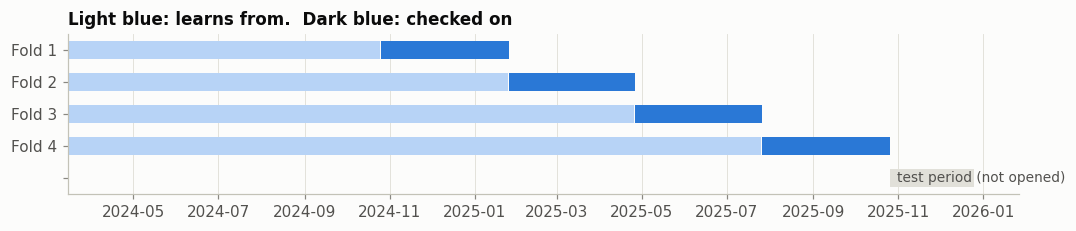

In [5]:
fig, ax = plt.subplots(figsize=(10, 2.2))
t0 = day["datetime"].min()
for f in folds:
    y = N_FOLDS - f["fold"]
    ax.barh(y, (f["start"] - t0).days, left=t0, color=BLUE_LIGHT, height=0.55)
    ax.barh(y, (f["end"] - f["start"]).days, left=f["start"], color=BLUE, height=0.55)
ax.barh(-1, 60, left=TEST_START, color=GRID, height=0.55)
ax.text(TEST_START + pd.Timedelta("5D"), -1, "test period (not opened)", va="center", fontsize=9, color=INK2)
ax.set_yticks(list(range(N_FOLDS - 1, -1, -1)) + [-1], [f"Fold {f['fold']}" for f in folds] + [""])
ax.grid(axis="y", visible=False)
ax.set_title("Light blue: learns from.  Dark blue: checked on", fontsize=11)
plt.tight_layout(); plt.show()

## 4. The two benchmarks

### 4.1 Persistence: the naive rule

"Tomorrow will look like the last day we observed."

The forecast is made at 11:00 on the day before delivery. At that moment the current day is not over, so its afternoon output is not known yet. The last day that is **fully observed** is the day before that. Persistence therefore copies the load factor of the same hour **two days before delivery** (48 hours earlier).

Copying "the same hour yesterday" would use afternoon values that do not exist yet at 11:00. That would be a leak from the future, and it would make the naive rule look better than it can be in practice.

### 4.2 Elia's day-ahead forecast

The grid operator's own forecast, as published at 11:00 the day before (`dayahead11hforecast`, in MW). It is divided by the installed capacity to put it on the same 0 to 1 scale as the target. It is used as published, with no adjustment.

In [6]:
lf_by_hour = df.set_index("datetime")["lf"]                       # all hours, night included
day["persistence"] = (day["datetime"] - pd.Timedelta("48h")).map(lf_by_hour)
day["elia"] = day["dayahead11hforecast"] / day["monitoredcapacity"]

missing = day.loc[val, ["persistence", "elia"]].isna().sum()
print(f"Validation hours without a persistence value: {missing['persistence']}, without an Elia forecast: {missing['elia']}")
assert missing.sum() == 0

pd.DataFrame({NAMES[m]: score(day.loc[val, "lf"], day.loc[val, m]) for m in ["persistence", "elia"]}).T

Validation hours without a persistence value: 0, without an Elia forecast: 0


,MAE,RMSE,Bias
Persistence (naive rule),7.51,11.92,0.06
Elia day-ahead forecast,3.57,5.53,0.87


The table shows the two benchmarks over the four validation blocks together (one year of daylight hours). Elia's forecast is the one to beat. It is built with data we do not have, so coming close to it is already a good result.

## 5. Random forest

### 5.1 The model in short

A **decision tree** asks a series of yes/no questions about the inputs ("is the forecast sunlight above 400 W/m²?", "is the sun higher than 30°?") and ends in a leaf, which predicts the average load factor of the training hours that landed there. One deep tree learns the training data by heart and is unstable.

A **random forest** (Session 4) grows a few hundred trees and averages them. Two sources of randomness make the trees different from one another, so that their errors partly cancel:

- each tree is grown on a random resample of the training hours,
- at each question, the tree may only choose among a random subset of the inputs.

Why it suits this problem:

- Solar output behaves like a multiplication: the sunlight that is possible, times the share that gets through the cloud. Trees pick up this kind of interaction by themselves.
- A forest can only predict averages of load factors it has seen, so it never leaves the 0 to 1 range.
- It needs little tuning and no rescaling of the inputs.

What it assumes: that the future looks like the past. The link between weather and output must stay the same from the training period to the period being forecast.

### 5.2 The two settings we tune

| Setting | scikit-learn name | What it does | Values tried |
|---|---|---|---|
| Inputs offered at each question | `max_features` | The main lever. Fewer inputs: the trees differ more, but each tree is weaker. 1.0 means all inputs, which is plain bagging | 0.2, 1/3, 0.5, 1.0 |
| Smallest leaf | `min_samples_leaf` | The minimum number of training hours in a leaf. Larger leaves give smoother forecasts, which helps when the target is noisy and the history is short | 1, 5, 10, 20, 50 |

The number of trees is fixed at 300. Adding trees never makes a forest overfit: the score only settles.

Each of the 20 combinations is trained and checked on the four folds. The forecasts for the four blocks are then scored together.

In [7]:
def make_forest(max_features, min_samples_leaf):
    return RandomForestRegressor(n_estimators=N_TREES, max_features=max_features,
                                 min_samples_leaf=min_samples_leaf, n_jobs=-1, random_state=SEED)

def validate(make_model, features):
    # Forecast each validation block with a model that only saw earlier months.
    pred = pd.Series(np.nan, index=day.index)
    for f in folds:
        learn = day[day["datetime"] < f["start"]]
        check = day[day["fold"] == f["fold"]]
        model = make_model().fit(learn[features], learn["lf"])
        pred.loc[check.index] = np.clip(model.predict(check[features]), 0, 1)
    return pred

MAX_FEATURES = {"0.2": 0.2, "1/3": 1 / 3, "0.5": 0.5, "1.0": 1.0}
MIN_LEAF = [1, 5, 10, 20, 50]

start = time.time()
rows, preds = [], {}
for label, mf in MAX_FEATURES.items():
    for leaf in MIN_LEAF:
        p = validate(lambda: make_forest(mf, leaf), FEATURES)
        preds[(label, leaf)] = p
        rows.append({"max_features": label, "min_samples_leaf": leaf, **score(day.loc[val, "lf"], p[val])})
grid = pd.DataFrame(rows)
print(f"{len(grid)} combinations x {N_FOLDS} folds trained in {time.time() - start:.0f} seconds")

20 combinations x 4 folds trained in 109 seconds


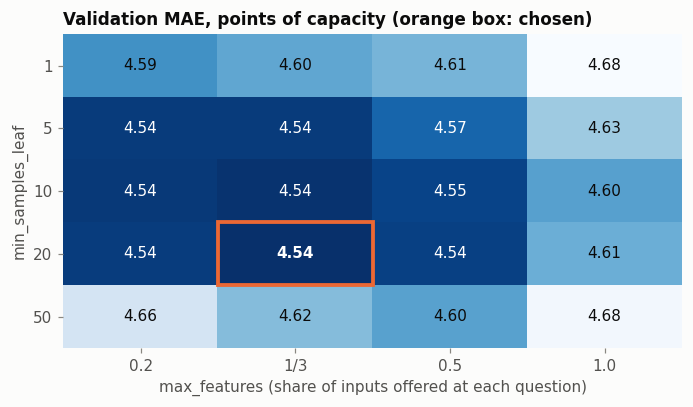

Chosen: max_features = 1/3, min_samples_leaf = 20  (validation MAE 4.54)
Gap between the best and the worst combination: 0.15 points


In [8]:
best = grid.sort_values("MAE").iloc[0]
BEST = {"max_features": MAX_FEATURES[best["max_features"]], "min_samples_leaf": int(best["min_samples_leaf"])}

heat = grid.pivot(index="min_samples_leaf", columns="max_features", values="MAE")[list(MAX_FEATURES)]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
im = ax.imshow(heat.values, cmap="Blues_r", aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        chosen = heat.index[i] == BEST["min_samples_leaf"] and heat.columns[j] == best["max_features"]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=10, fontweight="bold" if chosen else "normal",
                color="white" if v < heat.values.mean() else INK)
        if chosen:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=ORANGE, linewidth=2.5))
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_xlabel("max_features (share of inputs offered at each question)"); ax.set_ylabel("min_samples_leaf")
ax.set_title("Validation MAE, points of capacity (orange box: chosen)", fontsize=11)
ax.grid(visible=False)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout(); plt.show()

spread = grid["MAE"].max() - grid["MAE"].min()
print(f"Chosen: max_features = {best['max_features']}, min_samples_leaf = {BEST['min_samples_leaf']}  (validation MAE {best['MAE']:.2f})")
print(f"Gap between the best and the worst combination: {spread:.2f} points")

**Reading the chart.** Each cell is the validation MAE of one combination, darker is better. The rule is simple: keep the combination with the lowest MAE.

The printed gap between the best and the worst cell shows how much tuning matters here. If the gap is small, the forest is not sensitive to its settings, and the choice should not be over-interpreted.

### 5.3 Do the day-of-year inputs help?

Two of the inputs, `doy_sin` and `doy_cos`, tell the model where it is in the year. The sun's position is already given exactly by `solar_elevation` and the clear-sky columns, so the day of the year adds no physics. With under two years of history there is a risk: the forest could use it to remember "last March was cloudy", which says nothing about next March.

The check: run the chosen forest again without these two inputs, on the same folds. They are kept only if they lower the validation MAE.

In [9]:
NO_DOY = [c for c in FEATURES if c not in ("doy_sin", "doy_cos")]
p_with = preds[(best["max_features"], BEST["min_samples_leaf"])]
p_without = validate(lambda: make_forest(**BEST), NO_DOY)

doy_check = pd.DataFrame({"with day of year": score(day.loc[val, "lf"], p_with[val]),
                          "without day of year": score(day.loc[val, "lf"], p_without[val])}).T
keep_doy = doy_check.loc["with day of year", "MAE"] <= doy_check.loc["without day of year", "MAE"]
FINAL_FEATURES = FEATURES if keep_doy else NO_DOY
day["rf"] = p_with if keep_doy else p_without

display(doy_check)
print(f"Decision: day-of-year inputs are {'kept' if keep_doy else 'dropped'}. The forest uses {len(FINAL_FEATURES)} inputs.")

,MAE,RMSE,Bias
with day of year,4.54,6.83,1.32
without day of year,4.52,6.81,1.38


Decision: day-of-year inputs are dropped. The forest uses 26 inputs.


## 6. Comparison

### 6.1 The three forecasts over one validation year

In [10]:
MODELS = ["persistence", "elia", "rf"]
overall = pd.DataFrame({NAMES[m]: score(day.loc[val, "lf"], day.loc[val, m]) for m in MODELS}).T
overall["MAE vs Elia, %"] = (overall["MAE"] / overall.loc[NAMES["elia"], "MAE"] - 1) * 100
overall

,MAE,RMSE,Bias,"MAE vs Elia, %"
Persistence (naive rule),7.51,11.92,0.06,110.34
Elia day-ahead forecast,3.57,5.53,0.87,0.00
Random forest,4.52,6.81,1.38,26.55


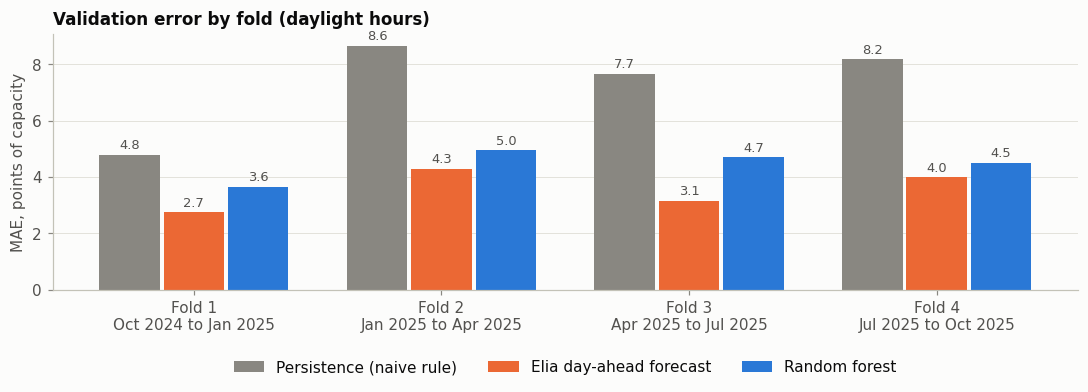

In [11]:
per_fold = pd.DataFrame({NAMES[m]: {f["fold"]: score(day.loc[day["fold"] == f["fold"], "lf"],
                                                      day.loc[day["fold"] == f["fold"], m])["MAE"] for f in folds}
                         for m in MODELS})
per_fold.index = [f"Fold {f['fold']}\n{f['start']:%b %Y} to {f['end'] - pd.Timedelta('1D'):%b %Y}" for f in folds]

fig, ax = plt.subplots(figsize=(10, 3.8))
x, w = np.arange(len(per_fold)), 0.26
for k, m in enumerate(MODELS):
    bars = ax.bar(x + (k - 1) * w, per_fold[NAMES[m]], width=w * 0.94, color=COLORS[m], label=NAMES[m])
    ax.bar_label(bars, fmt="%.1f", fontsize=8.5, color=INK2, padding=2)
ax.set_xticks(x, per_fold.index); ax.set_ylabel("MAE, points of capacity")
ax.set_title("Validation error by fold (daylight hours)", fontsize=11)
ax.grid(axis="x", visible=False); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout(); plt.show()

**Reading the table and the chart.**

- **MAE vs Elia** is the difference with Elia's forecast in percent. Below zero means better than Elia, above zero means worse.
- The folds follow the seasons. Errors in points of capacity are naturally larger in the sunny months, because output itself is larger. Compare the three bars inside a fold, not one fold with another.
- Fold 1 is the hardest for the forest: it has few months to learn from, and none of them is a winter month.

### 6.2 Where the errors are: by hour and by month

Hours are in Belgian local time.

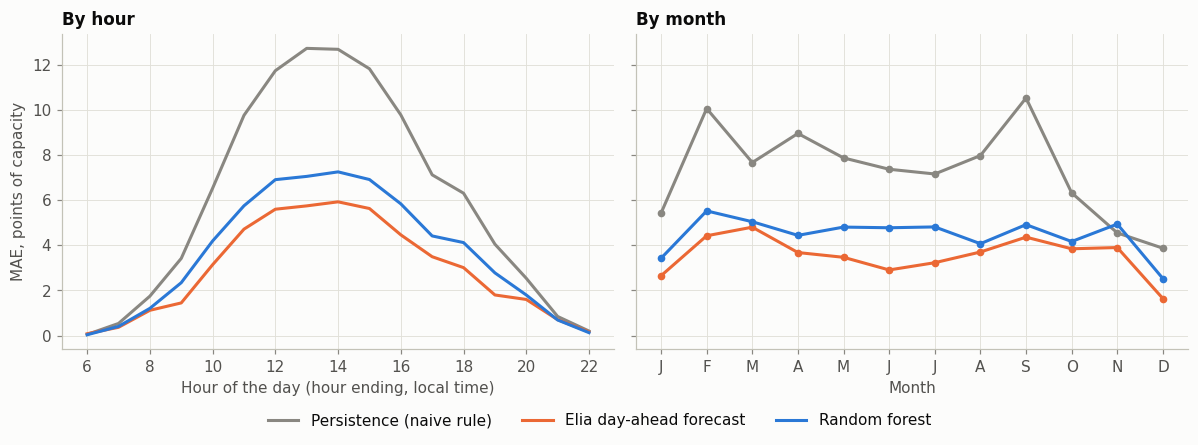

In [12]:
v = day[val].copy()
local = v["datetime"].dt.tz_convert("Europe/Brussels")
v["hour"], v["month"] = local.dt.hour, local.dt.month

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for m in MODELS:
    err = (v[m] - v["lf"]).abs() * 100
    by_hour = err.groupby(v["hour"]).mean()
    by_hour = by_hour[v.groupby("hour").size() >= 30]          # skip hours with very few daylight rows
    ax1.plot(by_hour.index, by_hour.values, color=COLORS[m], label=NAMES[m])
    by_month = err.groupby(v["month"]).mean()
    ax2.plot(by_month.index, by_month.values, color=COLORS[m], marker="o", markersize=4)
ax1.set_xlabel("Hour of the day (hour ending, local time)"); ax1.set_ylabel("MAE, points of capacity")
ax1.set_title("By hour", fontsize=11)
ax2.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax2.set_xlabel("Month"); ax2.set_title("By month", fontsize=11)
fig.legend(*ax1.get_legend_handles_labels(), ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.07))
plt.tight_layout(); plt.show()

### 6.3 One week, hour by hour

A week from the last validation block, to see what the forecasts look like next to what was actually produced. Night hours are drawn as zero.

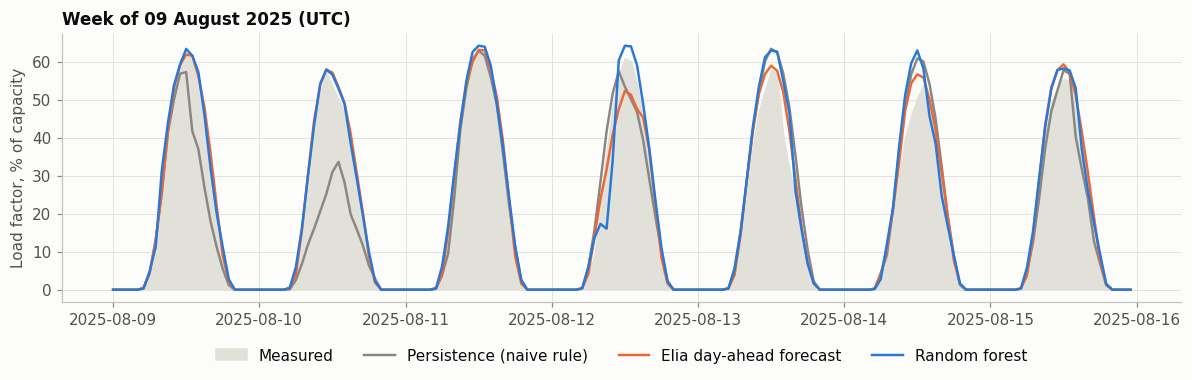

In [13]:
last = folds[-1]
week_start = (last["start"] + pd.Timedelta("14D")).normalize()
hours = pd.date_range(week_start, week_start + pd.Timedelta("7D"), freq="h", inclusive="left")
wk = day.set_index("datetime").reindex(hours)
actual = df.set_index("datetime")["lf"].reindex(hours)

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(hours, actual * 100, color=GRID, label="Measured")
for m in MODELS:
    ax.plot(hours, wk[m].fillna(0) * 100, color=COLORS[m], linewidth=1.6, label=NAMES[m])
ax.set_ylabel("Load factor, % of capacity")
ax.set_title(f"Week of {week_start:%d %B %Y} (UTC)", fontsize=11)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

## 7. Which inputs the forest relies on

**Permutation importance** (Session 4): take one input, shuffle its values across the hours so that it no longer carries information, and measure how much worse the forecast becomes. A large loss means the forest depends on that input.

It is measured on the last validation block, with a forest that learned from the months before it. So it is measured on data the forest has not seen, as the course recommends, without opening the test period.

Three cautions when reading it:

- **Inputs that carry the same information share their importance.** The four radiation columns and the clear-sky columns overlap heavily. Shuffling one of them costs little, because the others replace it. A short bar does not mean the information is useless.
- **Importance describes the model, not the world.** It is not a cause and effect statement.
- **It says nothing about direction**, only about how much the forest leans on the input.

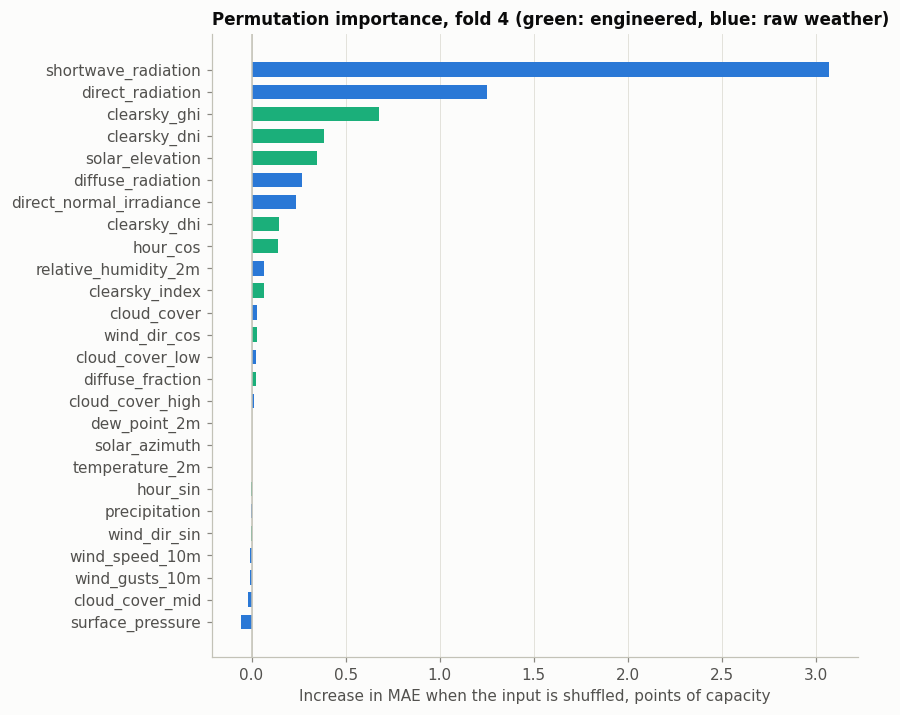

In [14]:
learn = day[day["datetime"] < last["start"]]
check = day[day["fold"] == last["fold"]]
forest = make_forest(**BEST).fit(learn[FINAL_FEATURES], learn["lf"])
perm = permutation_importance(forest, check[FINAL_FEATURES], check["lf"], scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
imp = (pd.Series(perm.importances_mean, index=FINAL_FEATURES) * 100).sort_values()

engineered = set(info["engineered"])
fig, ax = plt.subplots(figsize=(8, 6.6))
ax.barh(imp.index, imp.values, color=[AQUA if c in engineered else BLUE for c in imp.index], height=0.65)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_xlabel("Increase in MAE when the input is shuffled, points of capacity")
ax.set_title(f"Permutation importance, fold {last['fold']} (green: engineered, blue: raw weather)", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 8. Save

In [15]:
settings = {
    "province": PROVINCE,
    "model": "RandomForestRegressor",
    "params": {"n_estimators": N_TREES, **BEST, "random_state": SEED},
    "features": FINAL_FEATURES,
    "trained_on": "daylight hours of the training period",
    "validation": {"folds": [{"fold": f["fold"], "start": str(f["start"].date()), "end": str(f["end"].date())} for f in folds],
                   "scores": {m: {k: round(float(x), 3) for k, x in score(day.loc[val, "lf"], day.loc[val, m]).items()}
                              for m in MODELS}},
}
SETTINGS_FILE.write_text(json.dumps(settings, indent=2))

out = day.loc[val, ["datetime", "region", "fold", "lf"] + MODELS]
out.to_parquet(PRED_FILE, index=False)
print(f"Saved {SETTINGS_FILE}")
print(f"Saved {PRED_FILE}: {len(out):,} validation hours")

Saved model_settings.json
Saved cv_predictions.parquet: 4,668 validation hours


## What the next notebook receives

- **`model_settings.json`**: the forest's settings and its list of inputs. The evaluation notebook trains the forest once on the whole training period with these settings, then scores it on the test period. The fitted forest itself is not saved, because the file would be too large for the repository and it trains in a few seconds.
- **`cv_predictions.parquet`**: one row per validation hour with the measured load factor (`lf`) and the three forecasts (`persistence`, `elia`, `rf`), all on the 0 to 1 scale. Multiply by `monitoredcapacity` from `features_table.parquet` to get MW.

**To add another model** (for example XGBoost): write a `make_...` function like `make_forest`, pass it to `validate`, and add the result as a new column of `day`. The folds, the scores and the charts are then the same for every model, so the comparison stays fair.

**If the train/test cut changes** in `01_prepare_data.ipynb`: rerun `01`, `02` and this notebook. The folds are placed just before the test period automatically.